In [92]:
# LABORATORIO 10 - LEER UN MODELO LINEAL
# Integrantes: Susana García - Harriett Guzmán

# Importación de librerías
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import sklearn

from sklearn.dummy import DummyRegressor
from sklearn.preprocessing import OneHotEncoder
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

from sklearn.preprocessing import StandardScaler

from sklearn.linear_model import SGDRegressor

from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier

from sklearn.metrics import accuracy_score, recall_score

from sklearn.metrics import log_loss

from sklearn.metrics import confusion_matrix

from sklearn.metrics import RocCurveDisplay, roc_auc_score

In [93]:
# PREPARACIÓN - CARGA DE DATOS

# Cargar los archivos CSV locales
seg = pd.read_csv("insurance.csv")
tel = pd.read_csv("Telco-Customer-Churn.csv")

# Información de las bases de datos
print("Seguro:")
seg.info()

print("Telco:")
tel.info()

Seguro:
<class 'pandas.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   str    
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   str    
 5   region    1338 non-null   str    
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), str(3)
memory usage: 73.3 KB
Telco:
<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   Pho

In [94]:
# PREGUNTA 1 - ANÁLISIS DE SEGUROS

# Calcular promedio de los costos
promedio = seg["charges"].mean()

# Calcular mediana de los costos
mediana = seg["charges"].median()

# Calcular porcentaje de fumadores
porcentaje_fumadores = (
    (seg["smoker"] == "yes").mean() * 100
)

print("Respuestas: ")
print(f"Promedio de charges: ${promedio:,.2f}")
print(f"Mediana de charges: ${mediana:,.2f}")
print(f"Porcentaje de fumadores: {porcentaje_fumadores:.2f}%")

Respuestas: 
Promedio de charges: $13,270.42
Mediana de charges: $9,382.03
Porcentaje de fumadores: 20.48%


Pregunta 01: El promedio y la mediana de los costos médicos son diferentes porque existe clientes con gastos considerablemente elevados que aumentan el promedio. La mediana representa mejor el costo central, ya que es menos sensible a los valores extremos.

In [95]:
# PREGUNTA 2 - ANÁLISIS DE TELCO

# Convertir TotalCharges a valores numéricos
tel["TotalCharges"] = pd.to_numeric(
    tel["TotalCharges"],
    errors="coerce"
)

# Contar valores nulos
nulos = tel["TotalCharges"].isna().sum()

print("Cantidad de valores nulos:", nulos)

# Mostrar los clientes con valores nulos
print("Clientes por Nulo: ")

display(
    tel.loc[
        tel["TotalCharges"].isna(),
        ["customerID", "tenure", "MonthlyCharges", "TotalCharges"]
    ]
)

Cantidad de valores nulos: 11
Clientes por Nulo: 


,customerID,tenure,MonthlyCharges,TotalCharges
488,4472-LVYGI,0,52.55,NaN
753,3115-CZMZD,0,20.25,NaN
936,5709-LVOEQ,0,80.85,NaN
1082,4367-NUYAO,0,25.75,NaN
1340,1371-DWPAZ,0,56.05,NaN
3331,7644-OMVMY,0,19.85,NaN
3826,3213-VVOLG,0,25.35,NaN
4380,2520-SGTTA,0,20.00,NaN
5218,2923-ARZLG,0,19.70,NaN
6670,4075-WKNIU,0,73.35,NaN


Pregunta 02: Los valores nulos de TotalCharges corresponden a clientes con una antigüedad de cero meses. Esto puede indicar que son clientes nuevos que todavía no tienen cargos acumulados. Para el análisis se eliminarán estos registros, debido a que representan una proporción pequeña del conjunto de datos

In [96]:
# PARTE A - GRADIENT DESCENT

x = np.array([1, 2, 3.])
y = np.array([3, 5, 7.])

def descenso(alpha, pasos):
    b0 = b1 = 0.0

    for _ in range(pasos):
        e = y - (b0 + b1 * x)

        g0 = -2 * e.mean()
        g1 = -2 * (x * e).mean()

        b0 = b0 - alpha * g0
        b1 = b1 - alpha * g1

    costo = ((y - (b0 + b1 * x)) ** 2).mean()

    return b0, b1, costo

print("Un paso:", descenso(0.1, 1))
print("100 pasos, alpha=0.1:", descenso(0.1, 100))
print("100 pasos, alpha=0.01:", descenso(0.01, 100))
print("20 pasos, alpha=0.3:", descenso(0.3, 20))

Un paso: (np.float64(1.0), np.float64(2.266666666666667), np.float64(0.33185185185185256))
100 pasos, alpha=0.1: (np.float64(0.9911631576555288), np.float64(2.0038873421143735), np.float64(1.1202465672253998e-05))
100 pasos, alpha=0.01: (np.float64(0.9208271577099737), np.float64(2.034809170803847), np.float64(0.0008990740646563003))
20 pasos, alpha=0.3: (np.float64(-19639032.59679568), np.float64(-44644137.45283097), np.float64(1.3193892200663938e+16))


In [97]:
# PARTE B - COMPARACIÓN DE MODELOS

X = seg.drop(columns="charges")
y = seg["charges"]

X_tr, X_te, y_tr, y_te = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

NUM = ["age", "bmi", "children"]
CAT = ["sex", "smoker", "region"]

pre = ColumnTransformer([
    ("num", "passthrough", NUM),
    ("cat", OneHotEncoder(drop="first"), CAT)
])

# M0: modelo baseline
m0 = DummyRegressor()
m0.fit(X_tr, y_tr)

# M1: regresión con BMI
m1 = LinearRegression()
m1.fit(X_tr[["bmi"]], y_tr)

# M2: regresión con todas las variables
m2 = Pipeline([
    ("pre", pre),
    ("lr", LinearRegression())
])

m2.fit(X_tr, y_tr)

print("Los tres modelos fueron entrenados.")

Los tres modelos fueron entrenados.


In [98]:
# EVALUAR MAE, RMSE Y R2

resultados_modelos = []

def medir(nombre, modelo, cols=None):

    X_train = X_tr if cols is None else X_tr[cols]
    X_test = X_te if cols is None else X_te[cols]

    pred_train = modelo.predict(X_train)
    pred_test = modelo.predict(X_test)

    mae = mean_absolute_error(y_te, pred_test)
    rmse = np.sqrt(mean_squared_error(y_te, pred_test))
    r2_train = r2_score(y_tr, pred_train)
    r2_test = r2_score(y_te, pred_test)

    resultados_modelos.append({
        "Modelo": nombre,
        "MAE test": mae,
        "RMSE test": rmse,
        "R2 train": r2_train,
        "R2 test": r2_test
    })

    print(
        f"{nombre}: "
        f"MAE={mae:.2f}, "
        f"RMSE={rmse:.2f}, "
        f"R2 train={r2_train:.3f}, "
        f"R2 test={r2_test:.3f}"
    )

medir("M0 baseline", m0)
medir("M1 solo bmi", m1, ["bmi"])
medir("M2 completo", m2)

tabla_modelos = pd.DataFrame(resultados_modelos)

display(tabla_modelos)

M0 baseline: MAE=9593.34, RMSE=12465.61, R2 train=0.000, R2 test=-0.001
M1 solo bmi: MAE=9784.65, RMSE=12210.04, R2 train=0.039, R2 test=0.040
M2 completo: MAE=4181.19, RMSE=5796.28, R2 train=0.742, R2 test=0.784


,Modelo,MAE test,RMSE test,R2 train,R2 test
0,M0 baseline,9593.338461,12465.610442,0.000000,-0.000919
1,M1 solo bmi,9784.652596,12210.039191,0.038934,0.039702
2,M2 completo,4181.194474,5796.284659,0.741726,0.783593


Pregunta 5:
El R² del baseline en entrenamiento es cero porque el modelo predice siempre el promedio de la variable objetivo. En test puede ser ligeramente negativo, ya que el promedio de entrenamiento no necesariamente coincide con el de prueba. Un R² negativo significa que el modelo predice peor que utilizar directamente el promedio de los valores reales de test.

Pregunta 6:
Tener un coeficiente de BMI diferente de cero no significa que el modelo sea bueno. El coeficiente indica una relación lineal estimada, pero la calidad predictiva debe evaluarse mediante MAE y R². Si el error sigue siendo elevado y el R² es bajo, el modelo explica poca variabilidad de los costos.

In [99]:
# PREGUNTA 7 - ERRORES POR TIPO DE CLIENTE

res = y_te - m2.predict(X_te)

errores_fumadores = (
    res.abs()
    .groupby(X_te["smoker"])
    .mean()
)

print("Error absoluto promedio por grupo:")
display(errores_fumadores)

print(
    "Grupo con mayor error:",
    errores_fumadores.idxmax()
)

Error absoluto promedio por grupo:


smoker
no     3129.737535
yes    8348.079378
Name: charges, dtype: float64

Grupo con mayor error: yes


Un RMSE mayor que el MAE indica que existen errores grandes que reciben mayor penalización al elevarse al cuadrado. Al comparar fumadores y no fumadores, el grupo con mayor error absoluto promedio es aquel para el cual el modelo presenta menor precisión.

In [100]:
# PARTE C - INTERPRETACIÓN DE COEFICIENTES

lr = m2.named_steps["lr"]

nombres = m2.named_steps["pre"].get_feature_names_out()

coefs = pd.Series(
    lr.coef_,
    index=nombres
)

print("COEFICIENTES DEL MODELO:")
display(coefs.round(2))

print("Intercepto:", round(lr.intercept_, 2))

COEFICIENTES DEL MODELO:


num__age                   256.98
num__bmi                   337.09
num__children              425.28
cat__sex_male              -18.59
cat__smoker_yes          23651.13
cat__region_northwest     -370.68
cat__region_southeast     -657.86
cat__region_southwest     -809.80
dtype: float64

Intercepto: -11931.22


In [101]:
# PREGUNTA 8 - INTERPRETAR COEFICIENTES

for variable in [
    "num__age",
    "num__bmi",
    "num__children",
    "cat__smoker_yes",
    "cat__region_southwest"
]:
    valor = coefs[variable]

    print(f"{variable}: ${valor:,.2f}")

print("\nCategorías de referencia:")
print("smoker_yes se compara contra smoker_no.")
print("region_southwest se compara contra northeast.")

num__age: $256.98
num__bmi: $337.09
num__children: $425.28
cat__smoker_yes: $23,651.13
cat__region_southwest: $-809.80

Categorías de referencia:
smoker_yes se compara contra smoker_no.
region_southwest se compara contra northeast.


Pregunta 08: Cada coeficiente representa el cambio estimado en los cargos anuales, medidos en dólares, al aumentar una unidad de la variable correspondiente, manteniendo constantes las demás. Para age se interpreta por año adicional; para BMI, por punto adicional; y para children, por hijo adicional. Smoker_yes representa la diferencia entre fumadores y no fumadores. Region_southwest representa la diferencia respecto a northeast, que es la región base.

Pregunta 09: El intercepto representa el costo estimado para una persona con edad cero, BMI cero, sin hijos y perteneciente a las categorías de referencia. Aunque matemáticamente forma parte del modelo, no tiene una interpretación práctica razonable porque ese perfil no representa a un cliente realista.

In [102]:
# PREGUNTA 10 - COMPARACIÓN DE CLIENTES

# Dos clientes idénticos, excepto por fumar
dos = pd.DataFrame([
    {
        "age": 40,
        "sex": "male",
        "bmi": 30,
        "children": 1,
        "smoker": "no",
        "region": "northwest"
    },
    {
        "age": 40,
        "sex": "male",
        "bmi": 30,
        "children": 1,
        "smoker": "yes",
        "region": "northwest"
    }
])

pred_fumar = m2.predict(dos)

print("Costo no fumador:", pred_fumar[0])
print("Costo fumador:", pred_fumar[1])
print("Diferencia:", pred_fumar[1] - pred_fumar[0])

# Comparación por edad
edades = dos.iloc[[0, 0]].copy()
edades.loc[edades.index[1], "age"] = 50

# Restablecer índices para garantizar dos filas independientes
edades = pd.DataFrame([
    dict(age=40, sex="male", bmi=30, children=1,
         smoker="no", region="northwest"),
    dict(age=50, sex="male", bmi=30, children=1,
         smoker="no", region="northwest")
])

pred_edad = m2.predict(edades)

print("\nCosto a los 40 años:", pred_edad[0])
print("Costo a los 50 años:", pred_edad[1])
print("Diferencia:", pred_edad[1] - pred_edad[0])

Costo no fumador: 8496.595507039945
Costo fumador: 32147.724362801157
Diferencia: 23651.128855761213

Costo a los 40 años: 8496.595507039945
Costo a los 50 años: 11066.352565351886
Diferencia: 2569.7570583119414


Pregunta 10: La diferencia entre los dos primeros clientes coincide con el coeficiente smoker_yes. La diferencia entre los clientes de 40 y 50 años coincide con diez veces el coeficiente de age. Esto confirma que los coeficientes representan cambios en la predicción manteniendo constantes las demás variables.

Pregunta 11: La afirmación supone que reducir el BMI causa directamente una disminución del costo médico. Sin embargo, el modelo de regresión identifica asociaciones estadísticas y no demuestra causalidad. Tampoco garantiza que una intervención real produzca exactamente el cambio predicho.

In [103]:
# PARTE D - TRAMPA DE LA DUMMY

pre_todas = ColumnTransformer([
    ("num", "passthrough", NUM),
    ("cat", OneHotEncoder(), CAT)
])

m_trampa = Pipeline([
    ("pre", pre_todas),
    ("lr", LinearRegression())
])

m_trampa.fit(X_tr, y_tr)

nombres_t = (
    m_trampa.named_steps["pre"]
    .get_feature_names_out()
)

coefs_trampa = pd.Series(
    m_trampa.named_steps["lr"].coef_,
    index=nombres_t
)

display(coefs_trampa.round(2))

print(
    "Intercepto:",
    round(m_trampa.named_steps["lr"].intercept_, 2)
)

diferencia = np.abs(
    m_trampa.predict(X_te) - m2.predict(X_te)
).max()

print("Máxima diferencia de predicción:", diferencia)

num__age                   256.98
num__bmi                   337.09
num__children              425.28
cat__sex_female              9.30
cat__sex_male               -9.30
cat__smoker_no          -11825.56
cat__smoker_yes          11825.56
cat__region_northeast      459.59
cat__region_northwest       88.91
cat__region_southeast     -198.28
cat__region_southwest     -350.21
dtype: float64

Intercepto: -574.54
Máxima diferencia de predicción: 1.2369127944111824e-10


Pregunta 12: Predicción previa: se espera que scikit-learn pueda entrenar el modelo, aunque existan columnas redundantes. Las predicciones deberían mantenerse prácticamente iguales, pero los coeficientes pueden cambiar porque la representación no es única. La redundancia produce dependencia lineal entre columnas.

In [104]:
# PREGUNTA 13 - DIFERENCIA ENTRE COEFICIENTES DUMMY

diferencia_smoker = (
    coefs_trampa["cat__smoker_yes"]
    - coefs_trampa["cat__smoker_no"]
)

print("Diferencia entre smoker_yes y smoker_no:")
print(diferencia_smoker)

print("\nCoeficiente smoker_yes en M2:")
print(coefs["cat__smoker_yes"])

Diferencia entre smoker_yes y smoker_no:
23651.128855761228

Coeficiente smoker_yes en M2:
23651.12885576121


Pregunta 13: La diferencia entre los coeficientes smoker_yes y smoker_no del modelo con todas las categorías coincide aproximadamente con el coeficiente smoker_yes del modelo M2. Esto sucede porque ambos representan el contraste entre fumadores y no fumadores, aunque los coeficientes individuales se distribuyan de manera diferente.

In [105]:
# PREGUNTA 14 - COLUMNAS Y RANGO DE LA MATRIZ

Xm = pre_todas.fit_transform(X_tr)

Xm = np.c_[
    np.ones(len(Xm)),
    Xm
]

columnas = Xm.shape[1]
rango = np.linalg.matrix_rank(Xm)

print("Número de columnas:", columnas)
print("Rango de la matriz:", rango)
print("Columnas redundantes:", columnas - rango)

Número de columnas: 12
Rango de la matriz: 9
Columnas redundantes: 3


Pregunta 14: El rango es menor que el número de columnas porque las variables dummy incluyen todas las categorías y existe una columna de intercepto. Esto produce dependencias lineales: las columnas de cada variable categórica suman uno. Aparecen tres dependencias redundantes, correspondientes a sex, smoker y region.

In [106]:
# PREGUNTA 15 - CAMBIAR CATEGORÍA BASE

pre_se = ColumnTransformer([
    ("num", "passthrough", NUM),
    (
        "cat",
        OneHotEncoder(
            drop=["female", "no", "southeast"]
        ),
        CAT
    )
])

m_se = Pipeline([
    ("pre", pre_se),
    ("lr", LinearRegression())
])

m_se.fit(X_tr, y_tr)

coef_se = pd.Series(
    m_se.named_steps["lr"].coef_,
    index=m_se.named_steps["pre"].get_feature_names_out()
)

print("Coeficientes con southeast como base:")
display(coef_se.round(2))

print(
    "Máxima diferencia de predicción:",
    np.abs(
        m_se.predict(X_te) - m2.predict(X_te)
    ).max()
)

Coeficientes con southeast como base:


num__age                   256.98
num__bmi                   337.09
num__children              425.28
cat__sex_male              -18.59
cat__smoker_yes          23651.13
cat__region_northeast      657.86
cat__region_northwest      287.19
cat__region_southwest     -151.94
dtype: float64

Máxima diferencia de predicción: 1.382431946694851e-10


Pregunta 15: Cambiar la región base modifica la interpretación de los coeficientes regionales, pero no cambia las predicciones del modelo. Ahora el coeficiente de northeast representa la diferencia estimada en dólares entre northeast y southeast, manteniendo constantes las demás variables.

In [107]:
# PARTE E - COMPARACIÓN DE VARIABLES

coef_numericos = pd.Series({
    variable: coefs[f"num__{variable}"]
    for variable in NUM
})

desviaciones = X_tr[NUM].std()

comparacion = pd.DataFrame({
    "Coeficiente original": coef_numericos,
    "Desviación estándar": desviaciones,
    "Coeficiente ajustado": coef_numericos * desviaciones
})

print("\nOrden Original:")

print(
    comparacion["Coeficiente original"]
    .abs()
    .sort_values(ascending=False)
    .to_string()
)

print("\nOrden Estandarizado:")

print(
    comparacion["Coeficiente ajustado"]
    .abs()
    .sort_values(ascending=False)
    .to_string()
)


Orden Original:
children    425.278784
bmi         337.092552
age         256.975706

Orden Estandarizado:
age         3616.665841
bmi         2037.180299
children     517.131954


Pregunta 16: El orden de importancia puede cambiar porque los coeficientes originales están expresados en unidades diferentes. Al multiplicarlos por la desviación estándar de cada variable se obtiene una comparación más apropiada del cambio esperado en el costo ante una variación típica de cada característica.

In [108]:
# PREGUNTA 17 - STANDARD SCALER

pre_esc = ColumnTransformer([
    ("num", StandardScaler(), NUM),
    ("cat", OneHotEncoder(drop="first"), CAT)
])

m_escalado = Pipeline([
    ("pre", pre_esc),
    ("lr", LinearRegression())
])

m_escalado.fit(X_tr, y_tr)

coefs_escalados = pd.Series(
    m_escalado.named_steps["lr"].coef_,
    index=m_escalado.named_steps["pre"].get_feature_names_out()
)

print("Coeficientes escalados:")
display(coefs_escalados.round(2))

print("R2 original:", r2_score(y_te, m2.predict(X_te)))
print("R2 escalado:", r2_score(y_te, m_escalado.predict(X_te)))

Coeficientes escalados:


num__age                  3614.98
num__bmi                  2036.23
num__children              516.89
cat__sex_male              -18.59
cat__smoker_yes          23651.13
cat__region_northwest     -370.68
cat__region_southeast     -657.86
cat__region_southwest     -809.80
dtype: float64

R2 original: 0.7835929767120723
R2 escalado: 0.7835929767120722


Pregunta 17: Al estandarizar las variables numéricas cambian sus coeficientes porque ahora representan variaciones de una desviación estándar. Los coeficientes de las variables categóricas 0/1 permanecen prácticamente iguales porque no fueron escaladas. El R² no cambia de manera significativa porque la estandarización no elimina información del modelo.

In [109]:
# PARTE F - SGD REGRESSOR

pruebas = {
    "SGD sin escalar": Pipeline([
        ("pre", pre),
        ("sgd", SGDRegressor(random_state=42))
    ]),

    "SGD escalado": Pipeline([
        ("pre", pre_esc),
        ("sgd", SGDRegressor(random_state=42))
    ]),

    "SGD escalado, max_iter=5": Pipeline([
        ("pre", pre_esc),
        ("sgd", SGDRegressor(max_iter=5, random_state=42))
    ]),

    "SGD escalado, eta0=0.0001": Pipeline([
        ("pre", pre_esc),
        ("sgd", SGDRegressor(eta0=0.0001, random_state=42))
    ])
}

resultados_sgd = []

for nombre, modelo in pruebas.items():

    modelo.fit(X_tr, y_tr)

    pred = modelo.predict(X_te)

    r2 = r2_score(y_te, pred)
    mae = mean_absolute_error(y_te, pred)

    epocas = modelo.named_steps["sgd"].n_iter_

    resultados_sgd.append({
        "Modelo": nombre,
        "MAE": mae,
        "R2 test": r2,
        "Épocas": epocas
    })

tabla_sgd = pd.DataFrame(resultados_sgd)

display(tabla_sgd)

/Users/harriettguzman/PycharmProjects/Laboratorio 10/.venv/lib/python3.14/site-packages/sklearn/linear_model/_stochastic_gradient.py:1620: ConvergenceWarning: Maximum number of iteration reached before convergence. Consider increasing max_iter to improve the fit.
  warnings.warn(
/Users/harriettguzman/PycharmProjects/Laboratorio 10/.venv/lib/python3.14/site-packages/sklearn/linear_model/_stochastic_gradient.py:1620: ConvergenceWarning: Maximum number of iteration reached before convergence. Consider increasing max_iter to improve the fit.
  warnings.warn(


,Modelo,MAE,R2 test,Épocas
0,SGD sin escalar,3.955748e+09,-1.209349e+11,60
1,SGD escalado,4.204837e+03,7.828351e-01,57
2,"SGD escalado, max_iter=5",4.925424e+03,7.278793e-01,5
3,"SGD escalado, eta0=0.0001",5.666839e+03,6.281921e-01,1000


Pregunta 18: SGD sin escalar puede presentar inestabilidad porque las variables tienen magnitudes diferentes. Esto afecta el tamaño efectivo de las actualizaciones del gradiente y puede provocar pasos excesivamente grandes.

Pregunta 19: LinearRegression es conveniente para problemas pequeños o medianos porque calcula una solución de mínimos cuadrados sin necesidad de configurar una tasa de aprendizaje. SGDRegressor resulta útil para conjuntos de datos grandes o situaciones donde se requiere entrenamiento iterativo, aunque necesita un escalado adecuado y ajuste de hiperparámetros.

Pregunta 20: Con max_iter = 5 el algoritmo puede detenerse antes de alcanzar una solución adecuada. Con eta0 = 0.0001 la tasa de aprendizaje es tan pequeña que el avance puede ser insuficiente. Ambos casos muestran que el número de iteraciones y el tamaño del paso influyen en la convergencia.

In [110]:
# PARTE G - CLASIFICACIÓN TELCO

# Convertir TotalCharges a numérico
tel["TotalCharges"] = pd.to_numeric(
    tel["TotalCharges"],
    errors="coerce"
)

# Verificar valores faltantes
print("Valores nulos antes de limpiar:")
print(tel.isnull().sum()[tel.isnull().sum() > 0])

# Eliminar registros sin TotalCharges
tel = tel.dropna(subset=["TotalCharges"]).copy()

print("\nRegistros después de limpiar:", len(tel))

tel["churn"] = (
    tel["Churn"] == "Yes"
).astype(int)

NUM_T = [
    "tenure",
    "MonthlyCharges",
    "TotalCharges",
    "SeniorCitizen"
]

CAT_T = [
    "gender",
    "Partner",
    "Dependents",
    "PhoneService",
    "MultipleLines",
    "InternetService",
    "OnlineSecurity",
    "OnlineBackup",
    "DeviceProtection",
    "TechSupport",
    "StreamingTV",
    "StreamingMovies",
    "Contract",
    "PaperlessBilling",
    "PaymentMethod"
]

Xt = tel[NUM_T + CAT_T]
yt = tel["churn"]

# 80% temporal, 20% test
X_tmp, X_test, y_tmp, y_test = train_test_split(
    Xt,
    yt,
    test_size=0.2,
    stratify=yt,
    random_state=42
)

# 60% train, 20% validación
X_trn, X_val, y_trn, y_val = train_test_split(
    X_tmp,
    y_tmp,
    test_size=0.25,
    stratify=y_tmp,
    random_state=42
)

print("Train:", len(X_trn))
print("Validación:", len(X_val))
print("Test:", len(X_test))

Valores nulos antes de limpiar:
TotalCharges    11
dtype: int64

Registros después de limpiar: 7032
Train: 4218
Validación: 1407
Test: 1407


In [111]:
# MODELO BASELINE Y REGRESIÓN LOGÍSTICA

# Preparar variables numéricas y categóricas
pre_t = ColumnTransformer([
    ("num", StandardScaler(), NUM_T),
    (
        "cat",
        OneHotEncoder(
            drop="first",
            handle_unknown="ignore"
        ),
        CAT_T
    )
])

# Modelo baseline
base = DummyClassifier(strategy="most_frequent")
base.fit(X_trn, y_trn)

# Modelo de regresión logística
log = Pipeline([
    ("pre", pre_t),
    ("lr", LogisticRegression(max_iter=1000))
])

# Entrenar el modelo
log.fit(X_trn, y_trn)

print("Modelos de clasificación entrenados")
print("Baseline:", base.score(X_val, y_val))
print("Regresión logística:", log.score(X_val, y_val))

Modelos de clasificación entrenados
Baseline: 0.7341862117981521
Regresión logística: 0.7903340440653873


In [112]:
# PREGUNTA 21 - ACCURACY Y RECALL

pred_base = base.predict(X_val)
pred_log = log.predict(X_val)

accuracy_base = accuracy_score(y_val, pred_base)
recall_base = recall_score(y_val, pred_base)

accuracy_log = accuracy_score(y_val, pred_log)
recall_log = recall_score(y_val, pred_log)

comparacion_clasificacion = pd.DataFrame({
    "Modelo": ["Baseline", "Regresión logística"],
    "Accuracy": [accuracy_base, accuracy_log],
    "Recall": [recall_base, recall_log]
})

display(comparacion_clasificacion)

,Modelo,Accuracy,Recall
0,Baseline,0.734186,0.0
1,Regresión logística,0.790334,0.5


Pregunta 21: El baseline puede obtener un accuracy relativamente alto porque la mayoría de los clientes no cancela. Sin embargo, su recall para la clase positiva es cero, lo que significa que no identifica a los clientes que abandonan el servicio. Por eso accuracy no es suficiente para evaluar este problema.

In [113]:
# PREGUNTA 22 - SIGMOIDE

z = log.decision_function(X_val)

p = log.predict_proba(X_val)[:, 1]

sigmoide = 1 / (1 + np.exp(-z))

print(
    "Máxima diferencia:",
    np.abs(sigmoide - p).max()
)

print("Rango de z:", z.min(), z.max())
print("Rango de p:", p.min(), p.max())

print("z cuando p=0.5:", 0)

Máxima diferencia: 0.0
Rango de z: -6.528891599576256 1.9013950986488817
Rango de p: 0.0014584935984310716 0.8700493417994921
z cuando p=0.5: 0


Pregunta 22: La función sigmoide transforma cualquier valor real de z en una probabilidad entre cero y uno. Cuando z es cero, la probabilidad es 0.5. La diferencia entre la sigmoide calculada manualmente y predict_proba debe ser prácticamente cero.

In [114]:
# PREGUNTA 23 - LOG LOSS DE CINCO CLIENTES

reales = y_val.iloc[:5].to_numpy()

z5 = z[:5]
p5 = p[:5]

prob_real = np.where(
    reales == 1,
    p5,
    1 - p5
)

perdidas = -np.log(prob_real)

tabla_clientes = pd.DataFrame({
    "Cliente": range(1, 6),
    "¿Canceló?": reales,
    "z": z5,
    "p": p5,
    "Creyó en lo que pasó": prob_real,
    "Pérdida": perdidas
})

display(tabla_clientes.round(4))

print(
    "Cliente con mayor pérdida:",
    tabla_clientes.loc[
        tabla_clientes["Pérdida"].idxmax(),
        "Cliente"
    ]
)

# Comparar log-loss contra baseline prior
base_prior = DummyClassifier(strategy="prior")
base_prior.fit(X_trn, y_trn)

p_prior = base_prior.predict_proba(X_val)

loss_base = log_loss(y_val, p_prior)
loss_log = log_loss(y_val, log.predict_proba(X_val))

print("Log-loss baseline:", loss_base)
print("Log-loss logística:", loss_log)

,Cliente,¿Canceló?,z,p,Creyó en lo que pasó,Pérdida
0,1,0,-3.5151,0.0289,0.9711,0.0293
1,2,0,-2.9775,0.0485,0.9515,0.0497
2,3,1,-4.7529,0.0086,0.0086,4.7615
3,4,0,-3.5244,0.0286,0.9714,0.0290
4,5,1,0.9975,0.7306,0.7306,0.3139


Cliente con mayor pérdida: 3
Log-loss baseline: 0.5790505435964268
Log-loss logística: 0.42876933459512717


Pregunta 23: El cliente con mayor pérdida es aquel al que el modelo asignó una probabilidad muy baja al resultado que realmente ocurrió. Esto indica una predicción incorrecta realizada con mucha confianza. El log-loss penaliza especialmente este tipo de errores.

In [115]:
# PREGUNTA 24 - COEFICIENTES LOGÍSTICOS

coef_log = pd.Series(
    log.named_steps["lr"].coef_[0],
    index=log.named_steps["pre"].get_feature_names_out()
)

print("Coeficientes ordenados:")
display(coef_log.sort_values())

print("\nCoeficiente más negativo:")
print(coef_log.idxmin())
print(coef_log.min())

Coeficientes ordenados:


cat__Contract_Two year                       -1.325203
num__tenure                                  -1.301556
cat__Contract_One year                       -0.861965
cat__PhoneService_Yes                        -0.495906
cat__OnlineSecurity_Yes                      -0.423775
cat__TechSupport_Yes                         -0.388552
cat__Dependents_Yes                          -0.286020
num__MonthlyCharges                          -0.283802
cat__PaymentMethod_Credit card (automatic)   -0.185153
cat__StreamingMovies_No internet service     -0.150403
cat__StreamingTV_No internet service         -0.150403
cat__TechSupport_No internet service         -0.150403
cat__DeviceProtection_No internet service    -0.150403
cat__OnlineBackup_No internet service        -0.150403
cat__InternetService_No                      -0.150403
cat__OnlineSecurity_No internet service      -0.150403
cat__OnlineBackup_Yes                        -0.131102
cat__gender_Male                             -0.055718
cat__Multi


Coeficiente más negativo:
cat__Contract_Two year
-1.325203306355276


Pregunta 24: El coeficiente más negativo corresponde a la característica que más reduce el logaritmo de las probabilidades relativas de cancelación, manteniendo constantes las demás variables. Un coeficiente negativo indica una menor tendencia estimada a cancelar el servicio. La interpretación debe realizarse considerando si la variable es numérica estandarizada o una categoría comparada con su referencia.

In [116]:
# PARTE H - EVALUACIÓN POR UMBRALES

def resumen(umbral, y_real, prob):

    pred = (prob >= umbral).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_real,
        pred,
        labels=[0, 1]
    ).ravel()

    return {
        "umbral": umbral,
        "ofertas": tp + fp,
        "TP": tp,
        "FP": fp,
        "FN": fn,
        "TN": tn,
        "TPR": round(tp / (tp + fn), 3),
        "FPR": round(fp / (fp + tn), 3),
        "precision": round(tp / (tp + fp), 3)
        if tp + fp else None,
        "accuracy": round((tp + tn) / len(y_real), 3)
    }

tabla_umbrales = pd.DataFrame([
    resumen(u, y_val, p)
    for u in [0.7, 0.5, 0.3, 0.2]
])

display(tabla_umbrales)

,umbral,ofertas,TP,FP,FN,TN,TPR,FPR,precision,accuracy
0,0.7,89,73,16,301,1017,0.195,0.015,0.820,0.775
1,0.5,295,187,108,187,925,0.500,0.105,0.634,0.790
2,0.3,494,271,223,103,810,0.725,0.216,0.549,0.768
3,0.2,670,318,352,56,681,0.850,0.341,0.475,0.710


Pregunta 25: Al reducir el umbral, normalmente aumenta el TPR porque se identifican más clientes que cancelan. También aumenta el FPR porque se clasifican más clientes que no cancelan como positivos. La precisión puede disminuir al aumentar los falsos positivos. El modelo no cambia: únicamente cambia la regla para convertir probabilidades en clases.

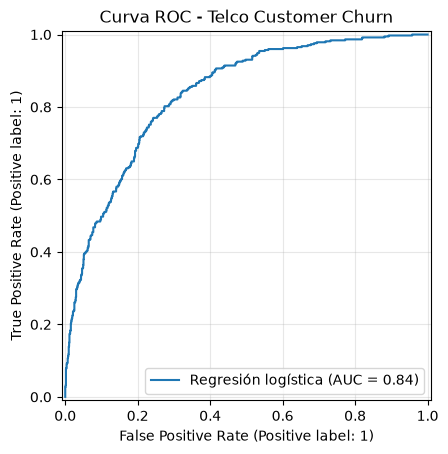

AUC regresión logística: 0.8356469138742357
AUC baseline: 0.5


In [117]:
# PREGUNTA 26 - CURVA ROC Y AUC

RocCurveDisplay.from_predictions(
    y_val,
    p,
    name="Regresión logística"
)

plt.title("Curva ROC - Telco Customer Churn")
plt.grid(alpha=0.3)
plt.show()

auc_log = roc_auc_score(y_val, p)

auc_base = roc_auc_score(
    y_val,
    base_prior.predict_proba(X_val)[:, 1]
)

print("AUC regresión logística:", auc_log)
print("AUC baseline:", auc_base)

Pregunta 26: El AUC representa la probabilidad de que el modelo asigne una puntuación de riesgo mayor a un cliente que cancela que a uno que no cancela, seleccionados al azar. Un AUC cercano a uno indica buena capacidad de discriminación. El baseline tiene AUC de 0.5 porque asigna la misma probabilidad a todos los clientes y no puede distinguir entre las clases.

In [118]:
# PREGUNTA 27 - UMBRAL ÓPTIMO POR COSTO

C_OFERTA = 50
C_PERDIDO = 300

filas = []

for u in np.arange(0.05, 0.96, 0.05).round(2):

    r = resumen(u, y_val, p)

    r["costo"] = (
        r["ofertas"] * C_OFERTA
        + r["FN"] * C_PERDIDO
    )

    filas.append(r)

tabla = pd.DataFrame(filas)

display(
    tabla[
        [
            "umbral",
            "ofertas",
            "TPR",
            "precision",
            "accuracy",
            "costo"
        ]
    ]
)

mejor_fila = tabla.loc[tabla["costo"].idxmin()]

umbral_optimo = float(mejor_fila["umbral"])

print("Umbral óptimo:", umbral_optimo)
print("Costo mínimo:", mejor_fila["costo"])

print(
    "Accuracy con umbral óptimo:",
    mejor_fila["accuracy"]
)

print(
    "Accuracy con umbral 0.5:",
    tabla.loc[
        np.isclose(tabla["umbral"], 0.5),
        "accuracy"
    ].iloc[0]
)

,umbral,ofertas,TPR,precision,accuracy,costo
0,0.05,1038,0.968,0.349,0.511,55500
1,0.10,870,0.930,0.400,0.611,51300
2,0.15,753,0.893,0.444,0.674,49650
3,0.20,670,0.850,0.475,0.710,50300
4,0.25,568,0.783,0.516,0.747,52700
5,0.30,494,0.725,0.549,0.768,55600
6,0.35,449,0.668,0.557,0.770,59650
7,0.40,393,0.612,0.583,0.780,63150
8,0.45,346,0.561,0.607,0.787,66500
9,0.50,295,0.500,0.634,0.790,70850


Umbral óptimo: 0.15
Costo mínimo: 49650.0
Accuracy con umbral óptimo: 0.674
Accuracy con umbral 0.5: 0.79


Pregunta 27: El umbral óptimo es el que produce el menor costo total en validación. Este umbral no necesariamente maximiza el accuracy, porque el objetivo de negocio consiste en reducir el costo de las ofertas y de los clientes perdidos. Por eso debe priorizarse la métrica económica definida para el problema.

In [119]:
# PREGUNTA 28 - RELACIÓN ENTRE COSTOS

relacion = C_OFERTA / C_PERDIDO

print("Costo de oferta:", C_OFERTA)
print("Costo de pérdida:", C_PERDIDO)

print("Relación:", relacion)

print("Umbral teórico:", round(relacion, 4))
print("Umbral encontrado:", umbral_optimo)

Costo de oferta: 50
Costo de pérdida: 300
Relación: 0.16666666666666666
Umbral teórico: 0.1667
Umbral encontrado: 0.15


Pregunta 28: La relación entre el costo de la oferta y el costo de perder un cliente es 50/300 = 0.1667. Bajo el supuesto de que la oferta siempre evita la cancelación, conviene ofrecerla cuando la probabilidad de cancelación supera aproximadamente el 16.67 %. El umbral óptimo observado puede diferir ligeramente porque se evalúan umbrales discretos y una muestra finita.

In [120]:
# PREGUNTA 29 - EVALUACIÓN FINAL EN TEST

# Probabilidades sobre el conjunto de prueba
p_test = log.predict_proba(X_test)[:, 1]

# Aplicar el umbral elegido en validación
pred_test = (p_test >= umbral_optimo).astype(int)

# Matriz de confusión
matriz = confusion_matrix(
    y_test,
    pred_test,
    labels=[0, 1]
)

tn, fp, fn, tp = matriz.ravel()

# Métricas
auc_test = roc_auc_score(y_test, p_test)

costo_test = (
    (tp + fp) * C_OFERTA
    + fn * C_PERDIDO
)

print("Resultados Finales: ")
print("Umbral seleccionado:", umbral_optimo)
print("AUC test:", round(auc_test, 4))
print("Costo total: Q", costo_test)

print("\nMatriz de confusión:")
display(
    pd.DataFrame(
        matriz,
        index=["Real No", "Real Sí"],
        columns=["Predicho No", "Predicho Sí"]
    )
)

print("\nTP:", tp)
print("FP:", fp)
print("FN:", fn)
print("TN:", tn)

Resultados Finales: 
Umbral seleccionado: 0.15
AUC test: 0.8358
Costo total: Q 50150

Matriz de confusión:


,Predicho No,Predicho Sí
Real No,584,449
Real Sí,36,338



TP: 338
FP: 449
FN: 36
TN: 584


Pregunta 29: El umbral se seleccionó utilizando el conjunto de validación para evitar que las decisiones de ajuste dependieran del conjunto de prueba. Test se reserva para una evaluación final e independiente. Si se hubiera elegido el umbral observando los resultados de test, la estimación del rendimiento podría ser demasiado optimista y no representar adecuadamente el comportamiento con clientes nuevos.

In [121]:
# TABLA RESUMEN FINAL DEL LABORATORIO 10

resumen_final = pd.DataFrame([
    {
        "Experimento": "B - M0 baseline",
        "Métrica clave": "MAE test",
        "Valor": round(tabla_modelos.iloc[0]["MAE test"], 3),
        "Aprendizaje": "Referencia para comparar modelos."
    },
    {
        "Experimento": "B - M2 completo",
        "Métrica clave": "MAE / R2 test",
        "Valor": (
            f"{tabla_modelos.iloc[2]['MAE test']:.2f} / "
            f"{tabla_modelos.iloc[2]['R2 test']:.3f}"
        ),
        "Aprendizaje": "Las variables adicionales mejoran la predicción."
    },
    {
        "Experimento": "C - Coeficiente smoker",
        "Métrica clave": "Dólares",
        "Valor": round(coefs["cat__smoker_yes"], 2),
        "Aprendizaje": "Fumar se asocia con mayores costos."
    },
    {
        "Experimento": "D - Modelo con trampa",
        "Métrica clave": "Máxima diferencia",
        "Valor": diferencia,
        "Aprendizaje": "Las predicciones pueden mantenerse aunque cambien las betas."
    },
    {
        "Experimento": "E - Variable más pesada",
        "Métrica clave": "Coeficiente estandarizado",
        "Valor": comparacion["Coeficiente ajustado"].abs().idxmax(),
        "Aprendizaje": "La escala influye en la comparación."
    },
    {
        "Experimento": "F - SGD sin escalar",
        "Métrica clave": "R2 test",
        "Valor": round(tabla_sgd.iloc[0]["R2 test"], 3),
        "Aprendizaje": "El escalado es importante para SGD."
    },
    {
        "Experimento": "G - Baseline Telco",
        "Métrica clave": "Accuracy / Recall",
        "Valor": f"{accuracy_base:.3f} / {recall_base:.3f}",
        "Aprendizaje": "Accuracy alto no garantiza buen recall."
    },
    {
        "Experimento": "G - Logística",
        "Métrica clave": "Log-loss / AUC",
        "Valor": f"{loss_log:.3f} / {auc_log:.3f}",
        "Aprendizaje": "Las probabilidades permiten evaluar el riesgo."
    },
    {
        "Experimento": "H - Umbral óptimo",
        "Métrica clave": "Umbral / Costo validación",
        "Valor": f"{umbral_optimo:.2f} / Q{mejor_fila['costo']:.2f}",
        "Aprendizaje": "El costo permite seleccionar el umbral."
    },
    {
        "Experimento": "H - Test final",
        "Métrica clave": "AUC / Costo test",
        "Valor": f"{auc_test:.3f} / Q{costo_test:.2f}",
        "Aprendizaje": "Test evalúa el modelo sin reajustarlo."
    }
])

display(resumen_final)

,Experimento,Métrica clave,Valor,Aprendizaje
0,B - M0 baseline,MAE test,9593.338,Referencia para comparar modelos.
1,B - M2 completo,MAE / R2 test,4181.19 / 0.784,Las variables adicionales mejoran la predicción.
2,C - Coeficiente smoker,Dólares,23651.13,Fumar se asocia con mayores costos.
3,D - Modelo con trampa,Máxima diferencia,0.0,Las predicciones pueden mantenerse aunque camb...
4,E - Variable más pesada,Coeficiente estandarizado,age,La escala influye en la comparación.
5,F - SGD sin escalar,R2 test,-120934850845.167999,El escalado es importante para SGD.
6,G - Baseline Telco,Accuracy / Recall,0.734 / 0.000,Accuracy alto no garantiza buen recall.
7,G - Logística,Log-loss / AUC,0.429 / 0.836,Las probabilidades permiten evaluar el riesgo.
8,H - Umbral óptimo,Umbral / Costo validación,0.15 / Q49650.00,El costo permite seleccionar el umbral.
9,H - Test final,AUC / Costo test,0.836 / Q50150.00,Test evalúa el modelo sin reajustarlo.


# Conclusión

En el Laboratorio 10 se analizaron modelos de regresión lineal y clasificación logística utilizando datos de seguros médicos y cancelación de servicios telefónicos. Se aprendió a comparar modelos contra un baseline, interpretar coeficientes, comprender el descenso de gradiente y reconocer la importancia de estandarizar variables. También se evaluaron clasificadores mediante accuracy, recall, log-loss, matriz de confusión, ROC y AUC. Finalmente, se comprobó que seleccionar un umbral según los costos del negocio puede ser más útil que buscar únicamente el mayor porcentaje de predicciones correctas.